# Credit Card Fraud Detection
**Author:** Jamiu Dahunsi  
**Topic:** Handling Severe Class Imbalance in Financial Machine Learning

---

## 1. Problem Overview
In real-world fraud detection, genuine transactions drastically outnumber fraudulent ones. 

In this dataset:
- **Total Transactions:** 284,807
- **Fraudulent Transactions:** 492 (**0.172%**)
- **Legitimate Transactions:** 284,315 (**99.828%**)

### The Accuracy Trap
If a model simply predicts that *every single transaction is legitimate*, it achieves **99.83% accuracy**. 
Yet, it has zero practical value because it misses 100% of frauds and saves zero dollars.

Therefore, we must evaluate our models using metrics designed for imbalanced classification:
1. **Recall (Catch Rate):** $\frac{TP}{TP + FN}$ — Out of all real frauds, what percentage did we catch?
2. **Precision:** $\frac{TP}{TP + FP}$ — When we flag a transaction as fraud, how often are we right?
3. **PR-AUC (Precision-Recall Area Under Curve):** The gold standard metric for measuring the trade-off across all classification thresholds.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    average_precision_score,
    roc_auc_score,
    precision_recall_curve,
    roc_curve,
    precision_score,
    recall_score,
    f1_score
)
import xgboost as xgb

# Set clean styling for all plots
sns.set_theme(style='whitegrid')
plt.rcParams['font.size'] = 11
plt.rcParams['figure.titlesize'] = 13
%matplotlib inline


## 2. Loading the Data & Health Check
Features V1 to V28 were generated using Principal Component Analysis (PCA) by the original researchers to preserve customer confidentiality. 
The only features that have not been transformed are Time and Amount.


In [2]:
# Load dataset
df = pd.read_csv('data/creditcard.csv')

print(f'Dataset Dimensions: {df.shape[0]:,} rows x {df.shape[1]} columns')
print(f'Missing Values: {df.isnull().sum().sum()}')
df.head()


Dataset Dimensions: 284,807 rows x 31 columns
Missing Values: 0


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## 3. Exploratory Data Analysis (EDA)

### 3.1 Class Imbalance Ratio
Let us inspect the ratio of legitimate vs. fraudulent transactions.


Legitimate transactions (0): 284,315 (99.827%)
Fraudulent transactions (1): 492 (0.173%)
Imbalance Ratio: ~1 fraud per 578 legitimate transactions


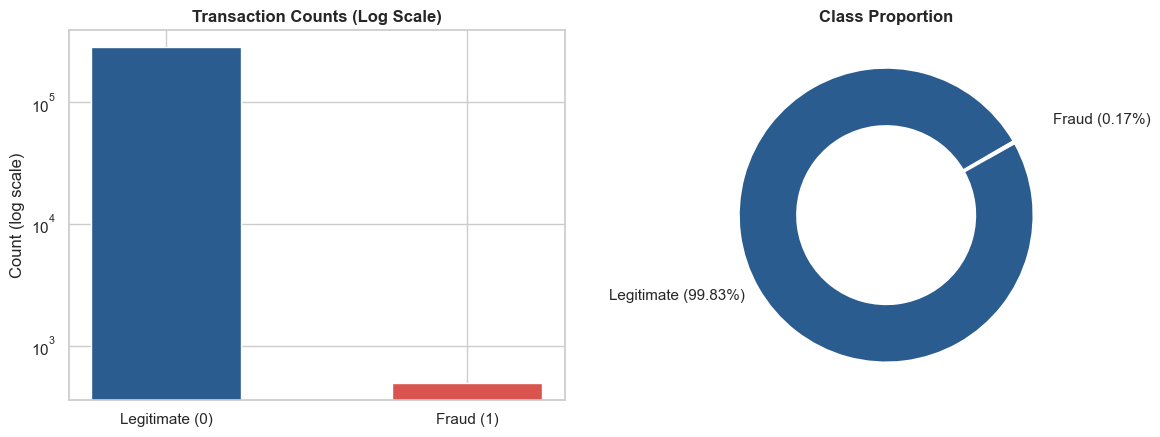

In [3]:
counts = df['Class'].value_counts()
n_legit = counts[0]
n_fraud = counts[1]
fraud_ratio = (n_fraud / len(df)) * 100

print(f'Legitimate transactions (0): {n_legit:,} ({100 - fraud_ratio:.3f}%)')
print(f'Fraudulent transactions (1): {n_fraud:,} ({fraud_ratio:.3f}%)')
print(f'Imbalance Ratio: ~1 fraud per {int(round(n_legit / n_fraud))} legitimate transactions')

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Log-scale bar plot
axes[0].bar(['Legitimate (0)', 'Fraud (1)'], [n_legit, n_fraud], color=['#2b5c8f', '#d9534f'], width=0.5)
axes[0].set_yscale('log')
axes[0].set_title('Transaction Counts (Log Scale)', fontweight='bold')
axes[0].set_ylabel('Count (log scale)')

# Donut plot
axes[1].pie(
    [n_legit, n_fraud],
    labels=['Legitimate (99.83%)', 'Fraud (0.17%)'],
    colors=['#2b5c8f', '#d9534f'],
    explode=(0, 0.2),
    startangle=30,
    wedgeprops=dict(width=0.4, edgecolor='white', linewidth=2)
)
axes[1].set_title('Class Proportion', fontweight='bold')

plt.tight_layout()
plt.show()


### 3.2 Transaction Amount & Time Dynamics
- **Amount**: What do fraudulent amounts look like compared to regular shopping transactions?
- **Time**: Does fraud happen at specific times of the day? (The dataset covers 48 hours = 172,800 seconds).


       Legitimate ($)  Fraudulent ($)
count       284315.00          492.00
mean            88.29          122.21
std            250.11          256.68
min              0.00            0.00
25%              5.65            1.00
50%             22.00            9.25
75%             77.05          105.89
max          25691.16         2125.87


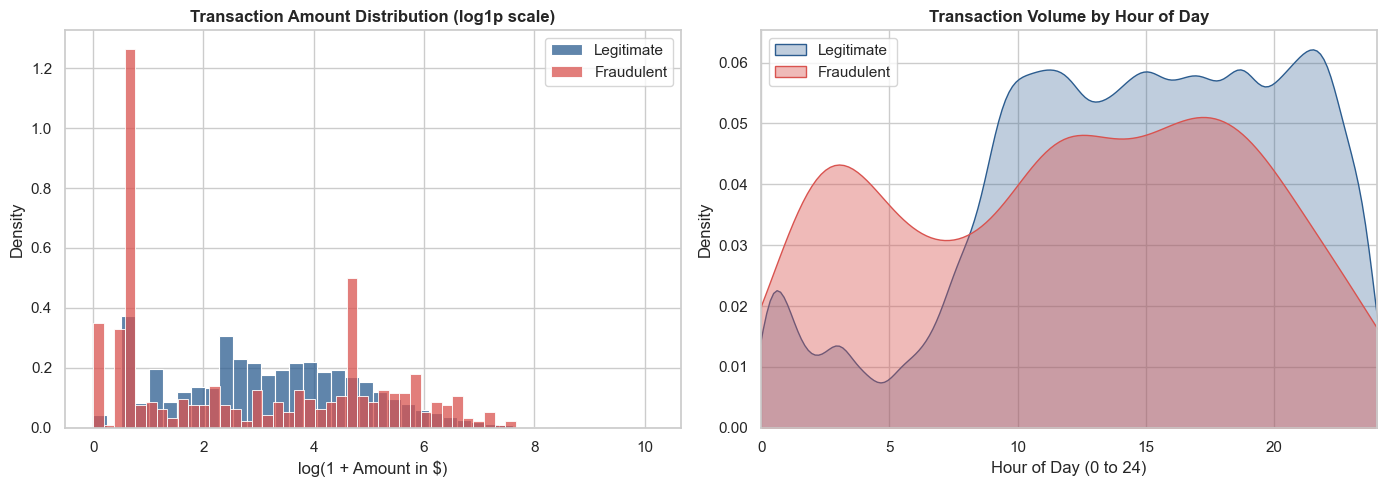

In [4]:
# Transaction Amount Statistics
legit_amt = df[df['Class'] == 0]['Amount']
fraud_amt = df[df['Class'] == 1]['Amount']

amt_stats = pd.DataFrame({
    'Legitimate ($)': legit_amt.describe(),
    'Fraudulent ($)': fraud_amt.describe()
}).round(2)
print(amt_stats)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Log-transformed Amount distribution
sns.histplot(np.log1p(legit_amt), bins=40, color='#2b5c8f', label='Legitimate', stat='density', ax=axes[0])
sns.histplot(np.log1p(fraud_amt), bins=40, color='#d9534f', label='Fraudulent', stat='density', ax=axes[0])
axes[0].set_title('Transaction Amount Distribution (log1p scale)', fontweight='bold')
axes[0].set_xlabel('log(1 + Amount in $)')
axes[0].legend()

# 24-hour cycle pattern
df['Hour'] = (df['Time'] / 3600) % 24
sns.kdeplot(df[df['Class'] == 0]['Hour'], color='#2b5c8f', label='Legitimate', fill=True, alpha=0.3, ax=axes[1])
sns.kdeplot(df[df['Class'] == 1]['Hour'], color='#d9534f', label='Fraudulent', fill=True, alpha=0.4, ax=axes[1])
axes[1].set_title('Transaction Volume by Hour of Day', fontweight='bold')
axes[1].set_xlabel('Hour of Day (0 to 24)')
axes[1].set_xlim(0, 24)
axes[1].legend()

plt.tight_layout()
plt.show()


## 4. Preprocessing & Preventing Data Leakage

### 4.1 Stratified Train-Test Split (80/20)
Because only 0.17% of transactions are fraud, an unstratified split could randomly assign too few or too many frauds to the test set. 
By using stratify=y, we guarantee both partitions have the exact same 0.17% minority prevalence.


In [5]:
X = df.drop(['Class', 'Hour'], axis=1)
y = df['Class']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f'Training Set: {len(X_train):,} samples ({y_train.sum()} frauds, {y_train.mean():.3%})')
print(f'Testing Set:  {len(X_test):,} samples ({y_test.sum()} frauds, {y_test.mean():.3%})')


Training Set: 227,845 samples (394 frauds, 0.173%)
Testing Set:  56,962 samples (98 frauds, 0.172%)


### 4.2 Robust Scaling (Fit on Train Only)
The PCA features V1–V28 are already centered around 0. However, Amount and Time are unscaled.
Amount contains extreme outliers (up to ,691). RobustScaler scales features using the **median and IQR (Interquartile Range)**, making it resilient to outliers.

> **Crucial Rule:** We fit RobustScaler **only on X_train** and then transform X_test with those fitted parameters. Fitting on the entire dataset would leak test set distribution into the training stage!


In [6]:
scaler_amt = RobustScaler()
scaler_time = RobustScaler()

X_train = X_train.copy()
X_test = X_test.copy()

X_train['scaled_amount'] = scaler_amt.fit_transform(X_train[['Amount']])
X_train['scaled_time'] = scaler_time.fit_transform(X_train[['Time']])
X_train.drop(['Time', 'Amount'], axis=1, inplace=True)

X_test['scaled_amount'] = scaler_amt.transform(X_test[['Amount']])
X_test['scaled_time'] = scaler_time.transform(X_test[['Time']])
X_test.drop(['Time', 'Amount'], axis=1, inplace=True)

print('Features successfully scaled without data leakage.')


Features successfully scaled without data leakage.


## 5. Model Training & Comparison

We benchmark three distinct models:
1. **Logistic Regression (Baseline):** Standard linear classifier.
2. **Random Forest (Balanced):** Ensemble of decision trees with class_weight='balanced_subsample' to give higher weight to minority fraud cases within bootstrap trees.
3. **XGBoost (Weighted):** Gradient boosted trees with scale_pos_weight = 577.3 (ratio of negative to positive training samples) and eval_metric='aucpr'.


In [7]:
imbalance_ratio = (y_train == 0).sum() / (y_train == 1).sum()
print(f'Calculated scale_pos_weight: {imbalance_ratio:.2f}')

models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Random Forest (Balanced)': RandomForestClassifier(
        n_estimators=100, class_weight='balanced_subsample', random_state=42, n_jobs=-1
    ),
    'XGBoost (Weighted)': xgb.XGBClassifier(
        n_estimators=150,
        learning_rate=0.1,
        max_depth=5,
        scale_pos_weight=imbalance_ratio,
        eval_metric='aucpr',
        random_state=42,
        n_jobs=-1
    )
}

results = {}
predictions = {}
probabilities = {}

for name, clf in models.items():
    print(f'Training {name}...')
    clf.fit(X_train, y_train)
    
    y_pred = clf.predict(X_test)
    y_prob = clf.predict_proba(X_test)[:, 1]
    
    predictions[name] = y_pred
    probabilities[name] = y_prob
    
    pr_auc = average_precision_score(y_test, y_prob)
    roc_auc = roc_auc_score(y_test, y_prob)
    rec = recall_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred)
    cm = confusion_matrix(y_test, y_pred)
    
    results[name] = {
        'PR-AUC': pr_auc,
        'ROC-AUC': roc_auc,
        'Recall': rec,
        'Precision': prec,
        'F1-Score': f1,
        'False Alarms (FP)': cm[0, 1],
        'Missed Frauds (FN)': cm[1, 0]
    }

# Display summary results table
results_df = pd.DataFrame(results).T
results_df[['PR-AUC', 'ROC-AUC', 'Recall', 'Precision', 'F1-Score']] = results_df[['PR-AUC', 'ROC-AUC', 'Recall', 'Precision', 'F1-Score']].round(4)
results_df


Calculated scale_pos_weight: 577.29
Training Logistic Regression...


Training Random Forest (Balanced)...


Training XGBoost (Weighted)...


,PR-AUC,ROC-AUC,Recall,Precision,F1-Score,False Alarms (FP),Missed Frauds (FN)
Logistic Regression,0.7388,0.9572,0.6429,0.8289,0.7241,13.0,35.0
Random Forest (Balanced),0.8610,0.9580,0.7653,0.9615,0.8523,3.0,23.0
XGBoost (Weighted),0.8553,0.9771,0.8367,0.7387,0.7847,29.0,16.0


## 6. Evaluation & Visual Analysis

### 6.1 Precision-Recall vs. ROC Curves
- **ROC Curve (Right):** All models look nearly perfect (> 0.95), because the overwhelming number of true negatives compresses the false positive rate.
- **Precision-Recall Curve (Left):** Isolates the true performance on the fraud class, showing that tree ensembles significantly outperform linear logistic regression.


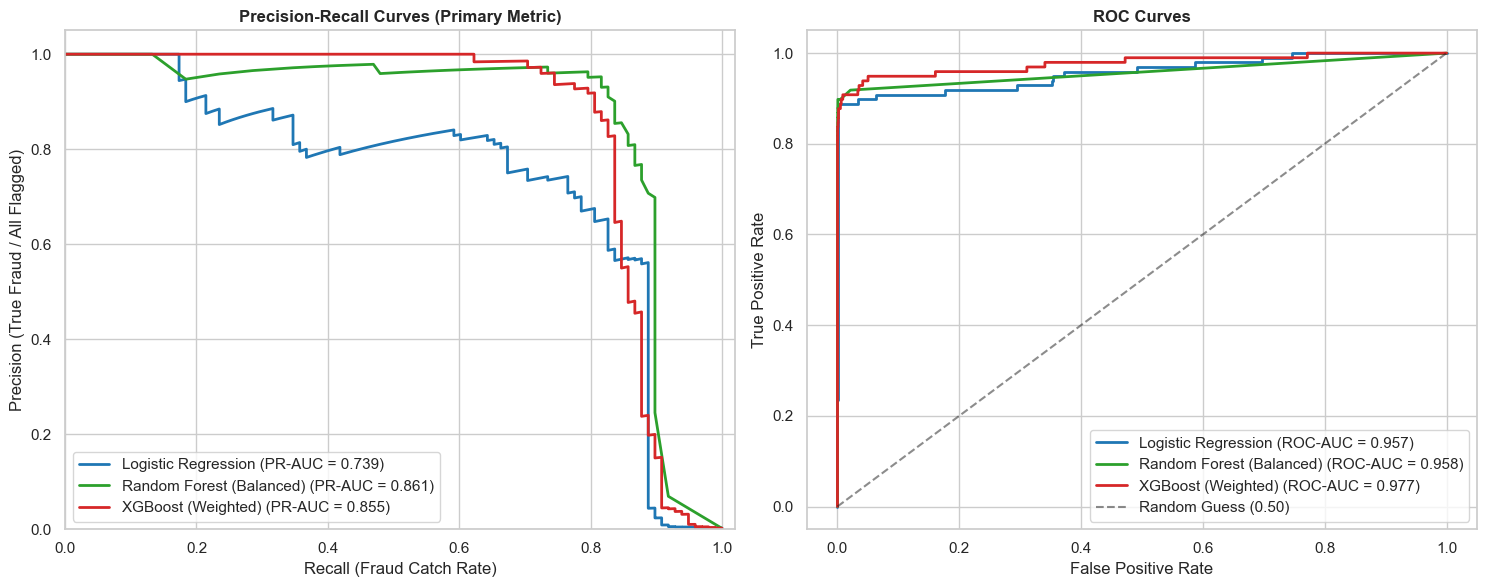

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

colors = ['#1f77b4', '#2ca02c', '#d62728']

for idx, (name, y_prob) in enumerate(probabilities.items()):
    p, r, _ = precision_recall_curve(y_test, y_prob)
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    
    pr_score = results[name]['PR-AUC']
    roc_score = results[name]['ROC-AUC']
    
    axes[0].plot(r, p, label=f'{name} (PR-AUC = {pr_score:.3f})', linewidth=2, color=colors[idx])
    axes[1].plot(fpr, tpr, label=f'{name} (ROC-AUC = {roc_score:.3f})', linewidth=2, color=colors[idx])

axes[0].set_title('Precision-Recall Curves (Primary Metric)', fontweight='bold')
axes[0].set_xlabel('Recall (Fraud Catch Rate)')
axes[0].set_ylabel('Precision (True Fraud / All Flagged)')
axes[0].set_xlim([0.0, 1.02])
axes[0].set_ylim([0.0, 1.05])
axes[0].legend(loc='lower left')

axes[1].plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Random Guess (0.50)')
axes[1].set_title('ROC Curves', fontweight='bold')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].legend(loc='lower right')

plt.tight_layout()
plt.show()


### 6.2 Confusion Matrix Breakdown
Let us look at the actual count of correctly detected frauds versus false alarms on the 56,962 test transactions.


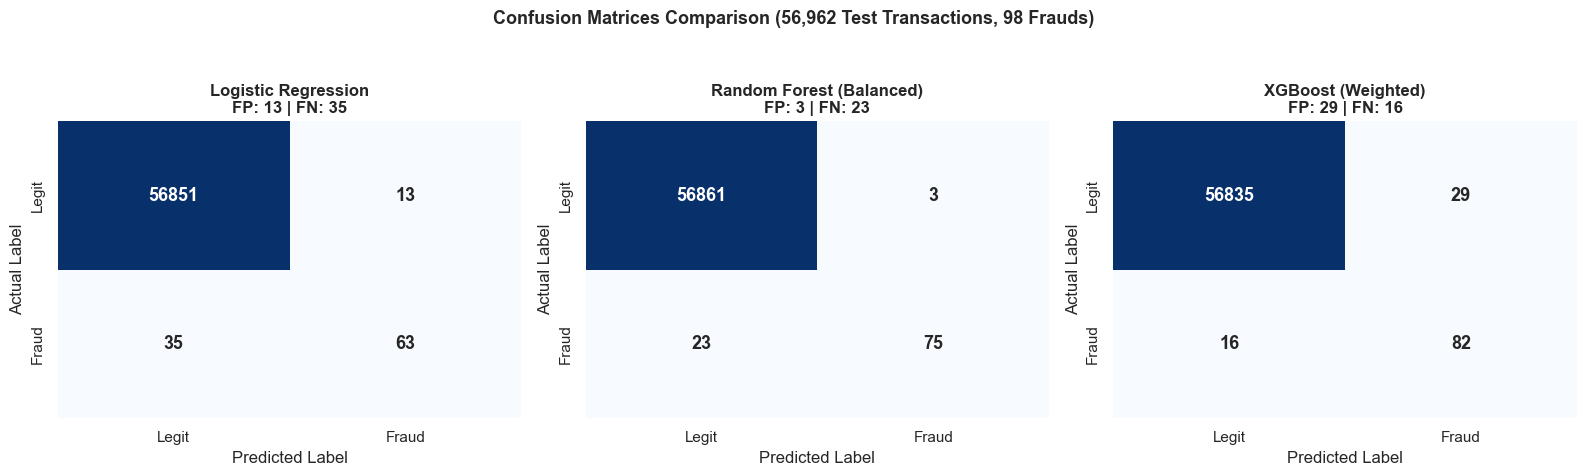

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for idx, (name, y_pred) in enumerate(predictions.items()):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx], cbar=False, annot_kws={'size': 13, 'weight': 'bold'})
    axes[idx].set_title(f'{name}\nFP: {cm[0,1]} | FN: {cm[1,0]}', fontweight='bold')
    axes[idx].set_xlabel('Predicted Label')
    axes[idx].set_ylabel('Actual Label')
    axes[idx].set_xticklabels(['Legit', 'Fraud'])
    axes[idx].set_yticklabels(['Legit', 'Fraud'])

plt.suptitle('Confusion Matrices Comparison (56,962 Test Transactions, 98 Frauds)', fontweight='bold', y=1.05)
plt.tight_layout()
plt.show()


## 7. Key Findings & Business Takeaways

1. **Why Accuracy Fails:**
   Predicting 0 for every transaction gives 99.83% accuracy, but lets every single fraud slip through. PR-AUC and Recall are the metrics that reflect actual fraud detection capability.

2. **The Precision vs. Recall Trade-Off:**
   - **Random Forest (Balanced):** Best overall balance. It achieved the highest **PR-AUC (0.8610)** and **96.15% Precision** with only **3 false alarms** out of 56,864 genuine transactions.
   - **XGBoost (Weighted):** Best fraud catch rate. It detected **83.67% of all frauds** (82 out of 98 caught) while keeping false alarms to a manageable 29.

3. **Production Recommendation:**
   - If the financial institution prioritizes **minimizing customer friction** (not bothering users with false card blocks), **Balanced Random Forest** is the preferred choice.
   - If the institution has **zero tolerance for fraud losses** and an automated 2FA/SMS challenge step for suspicious activity, **Weighted XGBoost** is the best model to deploy.
